In [1]:
import Pkg

project_dir = let dir = pwd()
    while !isfile(joinpath(dir, "Project.toml")) && dirname(dir) != dir
        dir = dirname(dir)
    end
    isfile(joinpath(dir, "Project.toml")) || error("No se encontró Project.toml; abre el notebook desde el repositorio.")
    dir
end

Pkg.activate(project_dir)

  Activating project at `c:\Users\Matias\guiado-proyectiles`


# Problema no lineal multiproyectil

El modelamiento de esta extensión [aquí](../../docs/04_modelo_multiproyectil.md). Tenemos el siguiente problema de Bolza:

$$
\min_{\substack{t_f>0\\w=(u,s)\in L^\infty([0,t_f],W)}}\quad
J(w,t_f):=\int_0^{t_f}\left(\beta+\frac{\alpha}{2}\sum_{i\in I}u_i(t)^2+\gamma\sum_{i\in I}s_i(t)\right)\,dt
$$

sujeto a la dinámica no lineal $\dot x=f(x,u)$, la condición inicial $x(0)=x_0$ y las condiciones terminales $h_i(x(t_f))\leq0$ para todo $i\in I$.

sujeto a la dinámica no lineal $\dot x=f(x,u)$, la condición inicial $x(0)=x_0$, las condiciones terminales $h_i(x(t_f))\leq0$ y las restricciones de trayectoria $r_{x_i}(t)^2+r_{y_i}(t)^2+s_i(t)\geq\varepsilon^2$ para todo $i\in I$.


### Modelamiento numérico

In [ ]:
using OptimalControl
using NLPModelsIpopt
using Plots


function evaluar_dinamica(x, w, rapidez_M, N)
    dx = similar(x)
    @inbounds for i in 1:N
        rx = x[i]
        ry = x[N + i]
        θ  = x[2N + i]

        c = cos(θ)
        s = sin(θ)
        dist = sqrt(rx^2 + ry^2) + 1e-4

        dx[i] = -rapidez_M * c
        dx[N + i] = -rapidez_M * s
        dx[2N + i] = (w[i] / rapidez_M) 
    end
    return dx
end


function evaluar_trayectoria_holgura(x, w, N)
    res = similar(x, N)
    @inbounds for i in 1:N
        res[i] = x[i]^2 + x[N + i]^2 + w[N + i]
    end
    return res
end


function evaluar_costo(w, alpha, beta, gamma, N)
    T = eltype(w)
    suma_u2 = zero(T)
    suma_s  = zero(T)

    @inbounds for i in 1:N
        suma_u2 += w[i]^2
        suma_s  += w[N + i]
    end

    return beta + 0.5 * alpha * suma_u2 + gamma * suma_s
end


function persecucion_multiproyectil_holgura(
    t0,
    x0;
    rapidez_M::Real = 5,
    alpha::Real = 1.0,
    beta::Real = 1.5,
    gamma::Real = 100.0,
    epsilon::Real = 5e-1,
    max_T::Real = 60,
    max_u::Real = 5,
)
    N = Int(length(x0) / 3)
    
    # Pasamos las cotas en forma vectorial
    epsilon_vectorial = fill(epsilon^2, N)
    lb_w = [fill(-max_u, N); zeros(N)]
    ub_w = [fill(max_u, N); epsilon_vectorial]

    ocp = @def begin
        tf ∈ R, variable

        # Usamos el estado en forma vectorial de la forma:
        # rx(t) = x[1:N], ry(t) = x[N+1:2N], θ(t) = x[2N+1:3N]
        t ∈ [t0, tf], time
        x ∈ R^(3*N), state
        w ∈ R^(2*N), control

        t0 <= tf <= max_T
        lb_w <= w(t) <= ub_w

        x(t0) == x0

        # Condición terminal y restricción de trayectoria con holgura
        x[1:N](tf).^2 .+ x[N+1:2N](tf).^2 <= epsilon_vectorial
        evaluar_trayectoria_holgura(x(t), w(t), N) >= epsilon_vectorial

        ẋ(t) == evaluar_dinamica(x(t), w(t), rapidez_M, N)

        ∫(evaluar_costo(w(t), alpha, beta, gamma, N)) → min
    end

    return ocp
end

persecucion_multiproyectil_holgura (generic function with 1 method)

### Utilidades de resolución

In [3]:
function resolver(problema)
    sol = @time solve(
        problema;
        #grid_size = 150,
        max_iter = 6000,
        display = false,
    )

    println("Estado: ", status(sol))
    println("Convergencia: ", successful(sol))
    println("Restricciones: ", constraints_violation(sol))

    return sol
end


function preparar_datos_iniciales(pos_target, datos_proyectiles)
    N = length(datos_proyectiles)
    datos_iniciales = zeros(3*N)

    xT, yT = pos_target
    matriz_datos = stack(datos_proyectiles, dims=1)

    rx0 = xT .- matriz_datos[:, 1]
    ry0 = yT .- matriz_datos[:, 2]
    θ0 = deg2rad.(matriz_datos[:, 3])

    datos_iniciales[1:N] = rx0
    datos_iniciales[N+1:2N] = ry0
    datos_iniciales[2N+1:3N] = θ0

    return datos_iniciales
end



preparar_datos_iniciales (generic function with 1 method)

### Utilidades para graficar

In [ ]:
RUTA_PLOTS = "multiproyectil/"
RUTA_RESULTADOS = joinpath(project_dir, "outputs", RUTA_PLOTS)
mkpath(RUTA_RESULTADOS)
LIM_X = (-150.0, 150.0)
LIM_Y = (-150.0, 150.0)


ESTILO_PLOTS = (
    titlefontsize = 24,
    guidefontsize = 24,
    tickfontsize = 18,
    legendfontsize = 18,
    legend = :outerright,
)

Plots.default(
    ; ESTILO_PLOTS...,
    linewidth = 3,
    grid = true,
    gridalpha = 0.8,
    left_margin = 14Plots.mm,
    bottom_margin = 10Plots.mm,
    top_margin = 5Plots.mm,
    right_margin = 5Plots.mm,
    size = (1600, 900),
)


function guardar_plot(grafico, nombre_archivo)
    Plots.savefig(grafico, joinpath(RUTA_RESULTADOS, nombre_archivo))
    return grafico
end


function anotar_angulo!(grafico, x, y, theta, lim_x, lim_y)
    half_width = 0.1 * (lim_x[2] - lim_x[1])
    half_height = 0.03 * (lim_y[2] - lim_y[1])
    fondo = Plots.Shape(
        [x - half_width, x + half_width, x + half_width, x - half_width],
        [y - half_height, y - half_height, y + half_height, y + half_height],
    )
    Plots.plot!(grafico, fondo; fillcolor = :white, fillalpha = 0.8, linecolor = :black, label = false)
    Plots.annotate!(grafico, x, y, Plots.text("θ₀ = $(round(Int, theta))°", 18, :black))
end


function plot_trayectorias(sol, pos_target, datos_proyectiles; lim_x::Tuple, lim_y::Tuple)
    tiempos = time_grid(sol)
    N = length(datos_proyectiles)
    
    grafico = plot(
        xlabel = "Eje X",
        ylabel = "Eje Y",
        title = "Trayectoria de múltiples proyectiles a un objetivo estacionario",
        aspect_ratio = :equal,
        grid = true,
        legend = ESTILO_PLOTS.legend,
        xlims = lim_x,
        ylims = lim_y,
    )

    scatter!(
        grafico, [pos_target[1]], [pos_target[2]];
        label="Objetivo",
        color=:black,
        marker=:square,
        markersize=8,
    )

    z = state(sol)

    colores = (
        "#0072B2",
        "#D55E00",
        "#009E73",
        "#CC79A7",
        "#A6761D",
        "#332288",
        "#882255",
        "#117733",
    )
    
    for i in 1:N
        θ_inicial = datos_proyectiles[i][3]
        color = colores[mod1(i, length(colores))]

        T_x = [pos_target[1] - z(t)[i] for t in tiempos]
        T_y = [pos_target[2] - z(t)[N + i] for t in tiempos]
        
        plot!(grafico, T_x, T_y; label = "Proyectil $i", color = color, linewidth = 3)
        scatter!(grafico, [T_x[1]], [T_y[1]]; label = false, color = color, marker = :circle, markersize = 7)

        label_idx = max(1, round(Int, length(T_x) * 0.25))
        anotar_angulo!(grafico, T_x[label_idx], T_y[label_idx], θ_inicial, lim_x, lim_y)
    end

    return guardar_plot(grafico, "trayectorias_N$(N).png")
end


function animar_trayectorias(
    sol,
    pos_target,
    datos_proyectiles;
    fps::Int = 30,
    # Muestrea la solución para generar alrededor de 100 fotogramas
    paso::Int = div(length(time_grid(sol)), 100),
    lim_x::Tuple,
    lim_y::Tuple,
    archivo::String = "trayectorias.gif"
)
    tiempos = time_grid(sol)
    N = length(datos_proyectiles)
    z = state(sol)

    # Precalculamos las trayectorias
    trayectorias_x = [[pos_target[1] - z(t)[i] for t in tiempos] for i in 1:N]
    trayectorias_y = [[pos_target[2] - z(t)[N + i] for t in tiempos] for i in 1:N]

    # Muestreamos los índices, incluyéndo el instante final
    indices = unique([1:paso:length(tiempos); length(tiempos)])

    anim = @animate for k in indices
        t_actual = round(tiempos[k], digits = 2)
        grafico = plot(
            xlabel = "Eje X",
            ylabel = "Eje Y",
            title = "Trayectoria de múltiples proyectiles (t = $(t_actual) s)",
            xlims = lim_x,
            ylims = lim_y,
            legend = ESTILO_PLOTS.legend,
            size = (1600, 900),
            left_margin = 14Plots.mm,
            bottom_margin = 10Plots.mm,
            top_margin = 5Plots.mm,
            right_margin = 5Plots.mm,
            grid = true,
            gridalpha = 0.8,
        )

        scatter!(
            grafico, [pos_target[1]], [pos_target[2]];
            label = "Objetivo", 
            color = :red,
            markersize = 9,
        )

        for i in 1:N
            θ_inicial = datos_proyectiles[i][3]
            etiqueta = "Proyectil $i (θ₀ = $(θ_inicial)°)"

            # Trayectoria recorrida hasta el instante k
            plot!(
                grafico,
                trayectorias_x[i][1:k],
                trayectorias_y[i][1:k];
                label = etiqueta,
                color = i,
                linewidth = 3,
            )

            # Eje X actual del proyectil
            scatter!(
                grafico,
                [trayectorias_x[i][k]],
                [trayectorias_y[i][k]],
                primary = false,
                color = i,
                markersize = 6,
            )
        end
    end

    ruta_archivo = joinpath(RUTA_RESULTADOS, archivo)
    mkpath(dirname(ruta_archivo))

    return gif(anim, ruta_archivo, fps = fps)
end


animar_trayectorias (generic function with 1 method)

## Experimentos


Iteración N = 1:
[[0.0, -110.0, 100.0]]
 36.731662 seconds (91.45 M allocations: 4.804 GiB, 4.50% gc time, 86.57% compilation time: <1% of which was recompilation)
Estado: first_order
Convergencia: true
Restricciones: 7.52148343607928e-12
 42.496232 seconds (120.72 M allocations: 6.200 GiB, 5.20% gc time, 88.39% compilation time: <1% of which was recompilation)


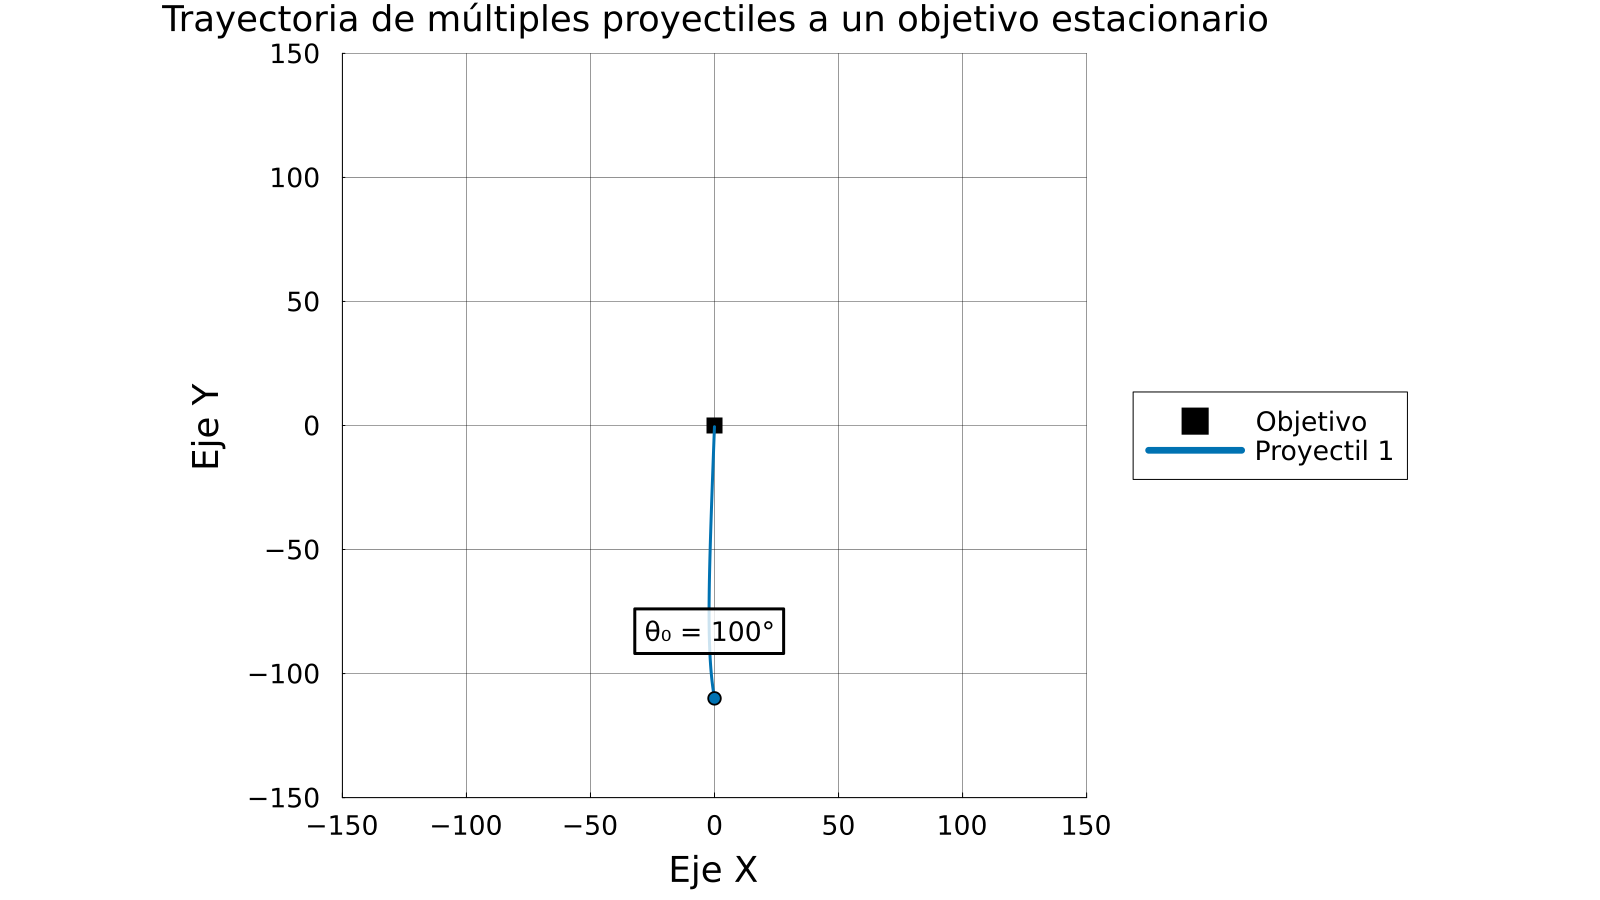


Iteración N = 2:
[[0.0, -110.0, 100.0], [-110.0, -80.0, 40.0]]
  9.870142 seconds (13.96 M allocations: 1.300 GiB, 1.96% gc time, 1.82% compilation time: <1% of which was recompilation)


[ Info: Saved animation to c:\Users\Matias\guiado-proyectiles\outputs\multiproyectil\trayectorias_N1.gif


Estado: first_order
Convergencia: true
Restricciones: 8.203197010558938e-10
  9.871013 seconds (13.96 M allocations: 1.300 GiB, 1.96% gc time, 1.82% compilation time: <1% of which was recompilation)


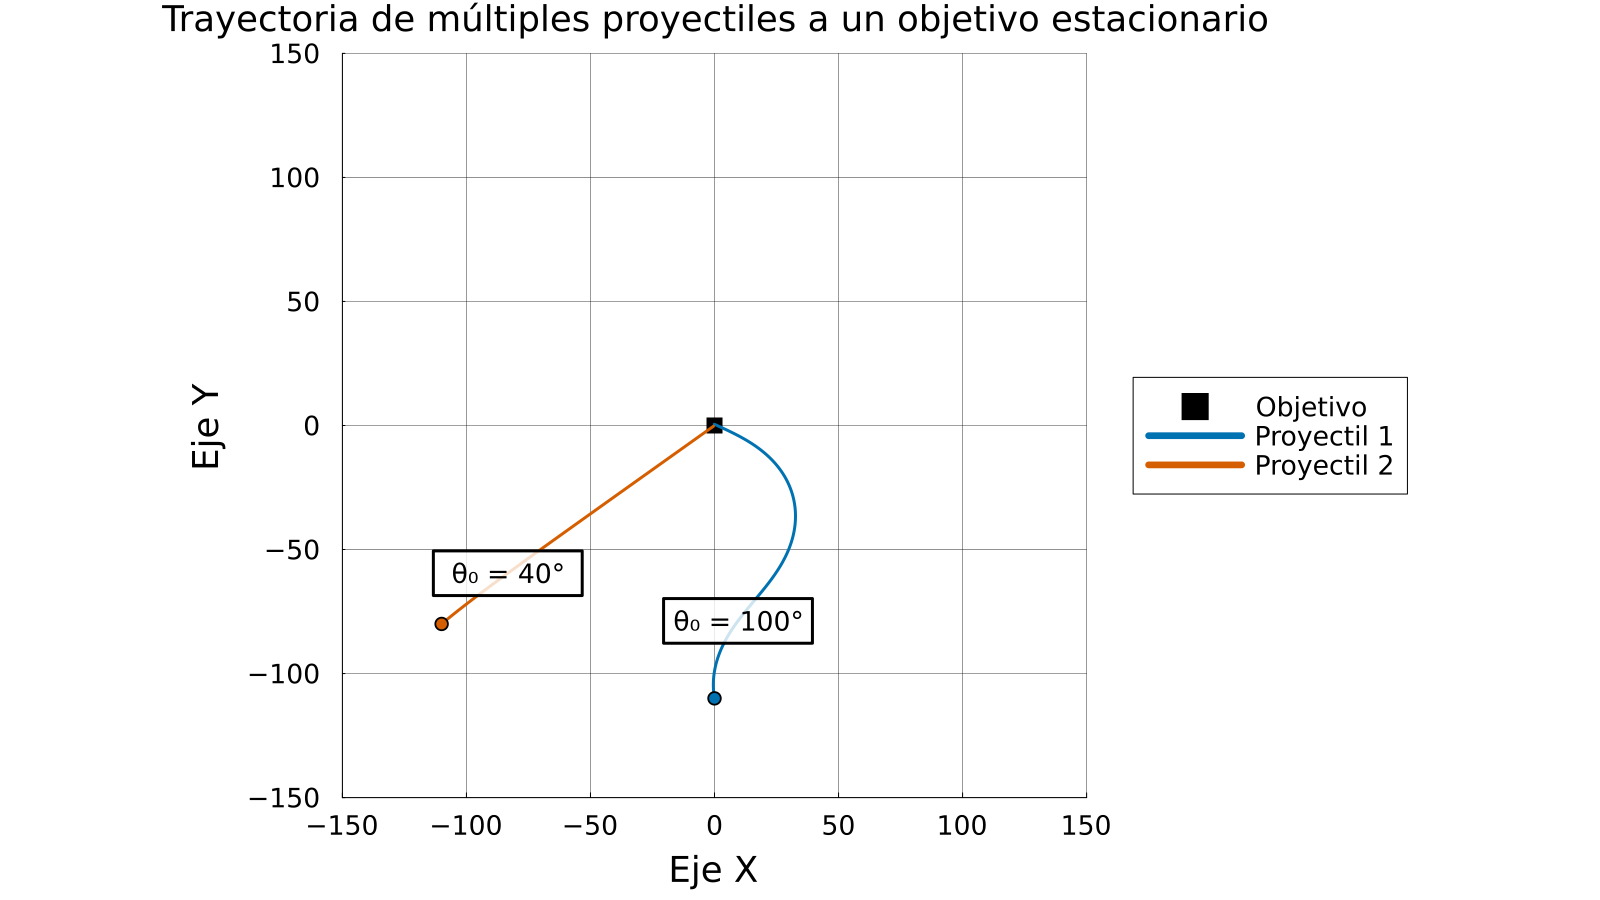


Iteración N = 3:
[[0.0, -110.0, 100.0], [-110.0, -80.0, 40.0], [-125.0, 10.0, 15.0]]
 66.922151 seconds (23.61 M allocations: 2.879 GiB, 0.50% gc time)


[ Info: Saved animation to c:\Users\Matias\guiado-proyectiles\outputs\multiproyectil\trayectorias_N2.gif


Estado: first_order
Convergencia: true
Restricciones: 1.1089101858985373e-11
 66.924867 seconds (23.61 M allocations: 2.879 GiB, 0.50% gc time)


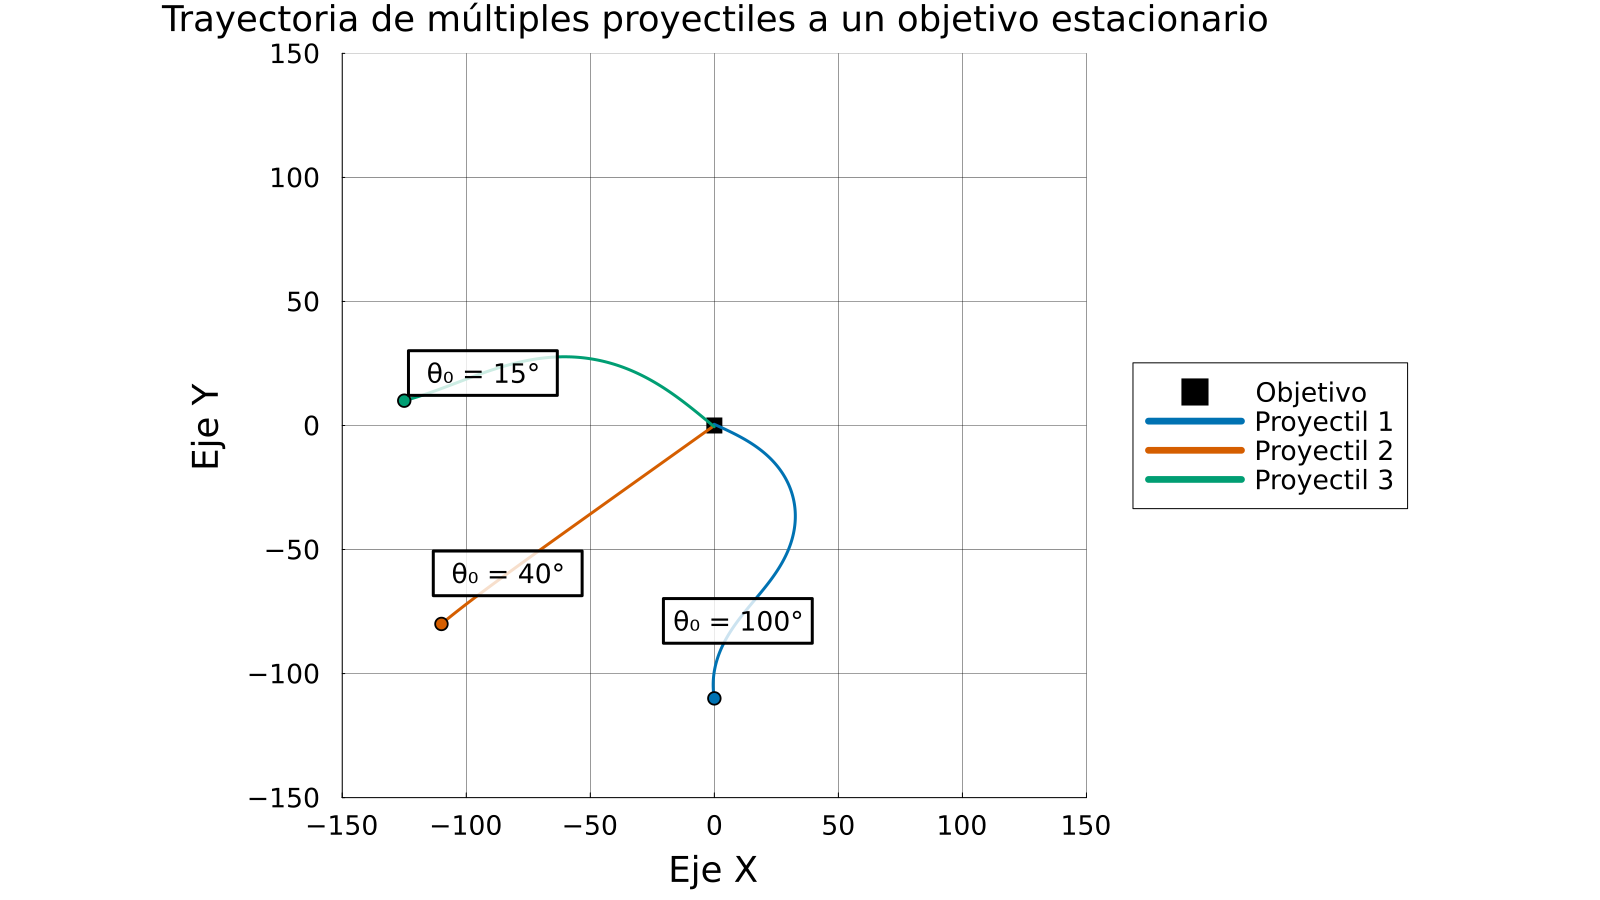


Iteración N = 4:
[[0.0, -110.0, 100.0], [-110.0, -80.0, 40.0], [-125.0, 10.0, 15.0], [-80.0, 105.0, -40.0]]
 69.977320 seconds (36.98 M allocations: 5.717 GiB, 1.59% gc time, 0.01% compilation time)


[ Info: Saved animation to c:\Users\Matias\guiado-proyectiles\outputs\multiproyectil\trayectorias_N3.gif


Estado: first_order
Convergencia: true
Restricciones: 1.1531083146110177e-6
 69.978160 seconds (36.98 M allocations: 5.718 GiB, 1.59% gc time, 0.01% compilation time)


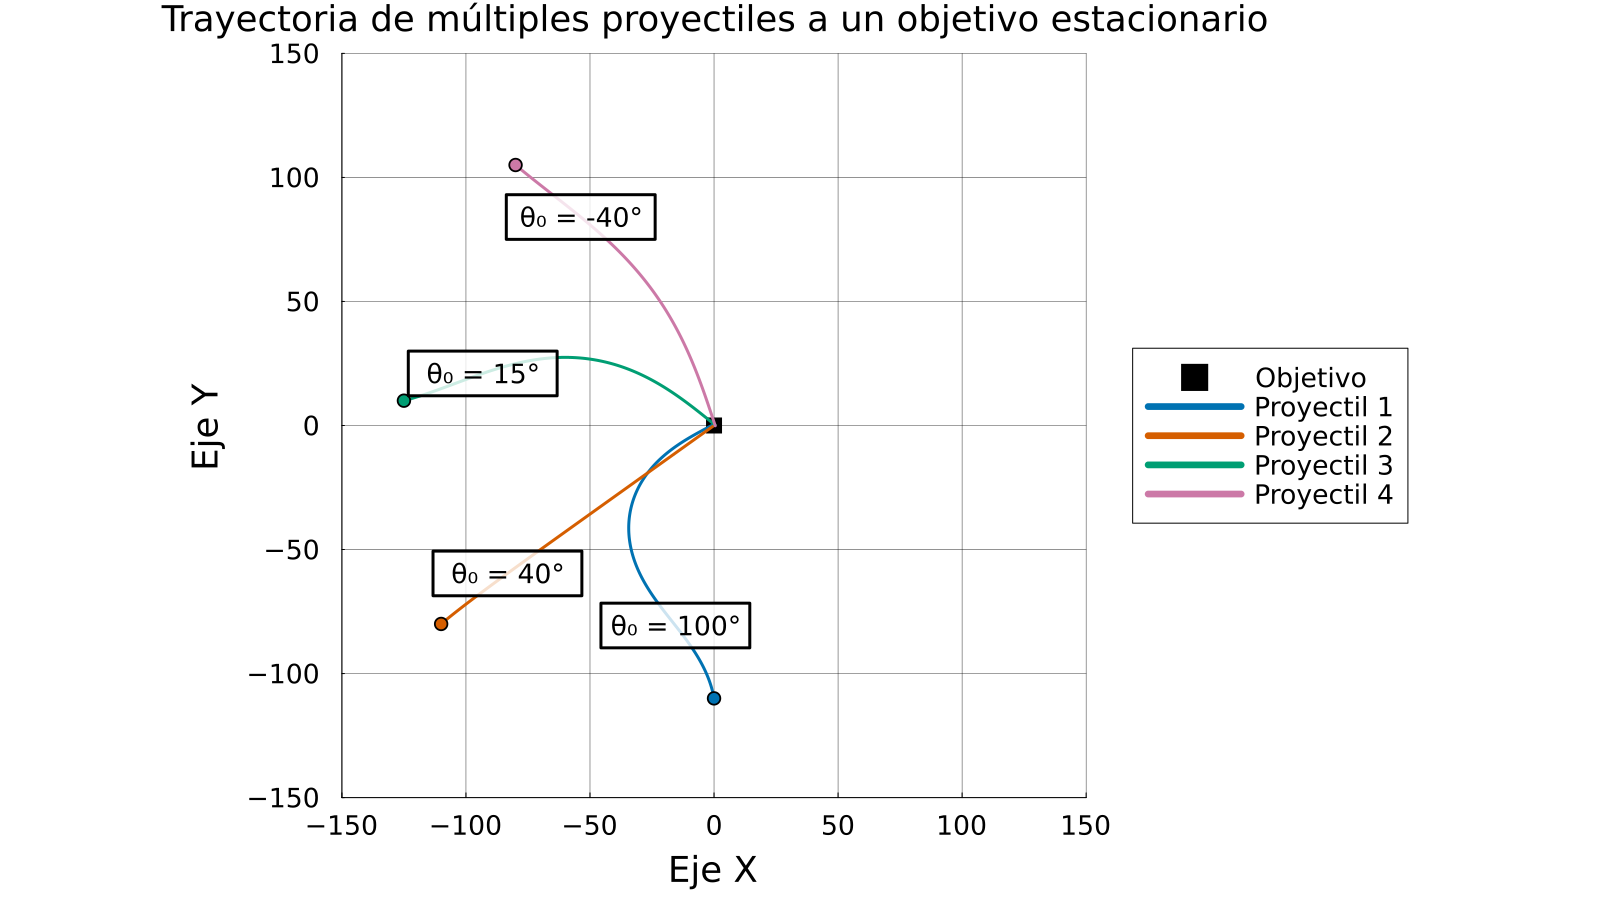


Iteración N = 5:
[[0.0, -110.0, 100.0], [-110.0, -80.0, 40.0], [-125.0, 10.0, 15.0], [-80.0, 105.0, -40.0], [10.0, 140.0, -115.0]]


[ Info: Saved animation to c:\Users\Matias\guiado-proyectiles\outputs\multiproyectil\trayectorias_N4.gif


153.873363 seconds (64.45 M allocations: 10.832 GiB, 1.08% gc time)
Estado: first_order
Convergencia: true
Restricciones: 5.614407827536638e-9
153.874228 seconds (64.45 M allocations: 10.832 GiB, 1.08% gc time)


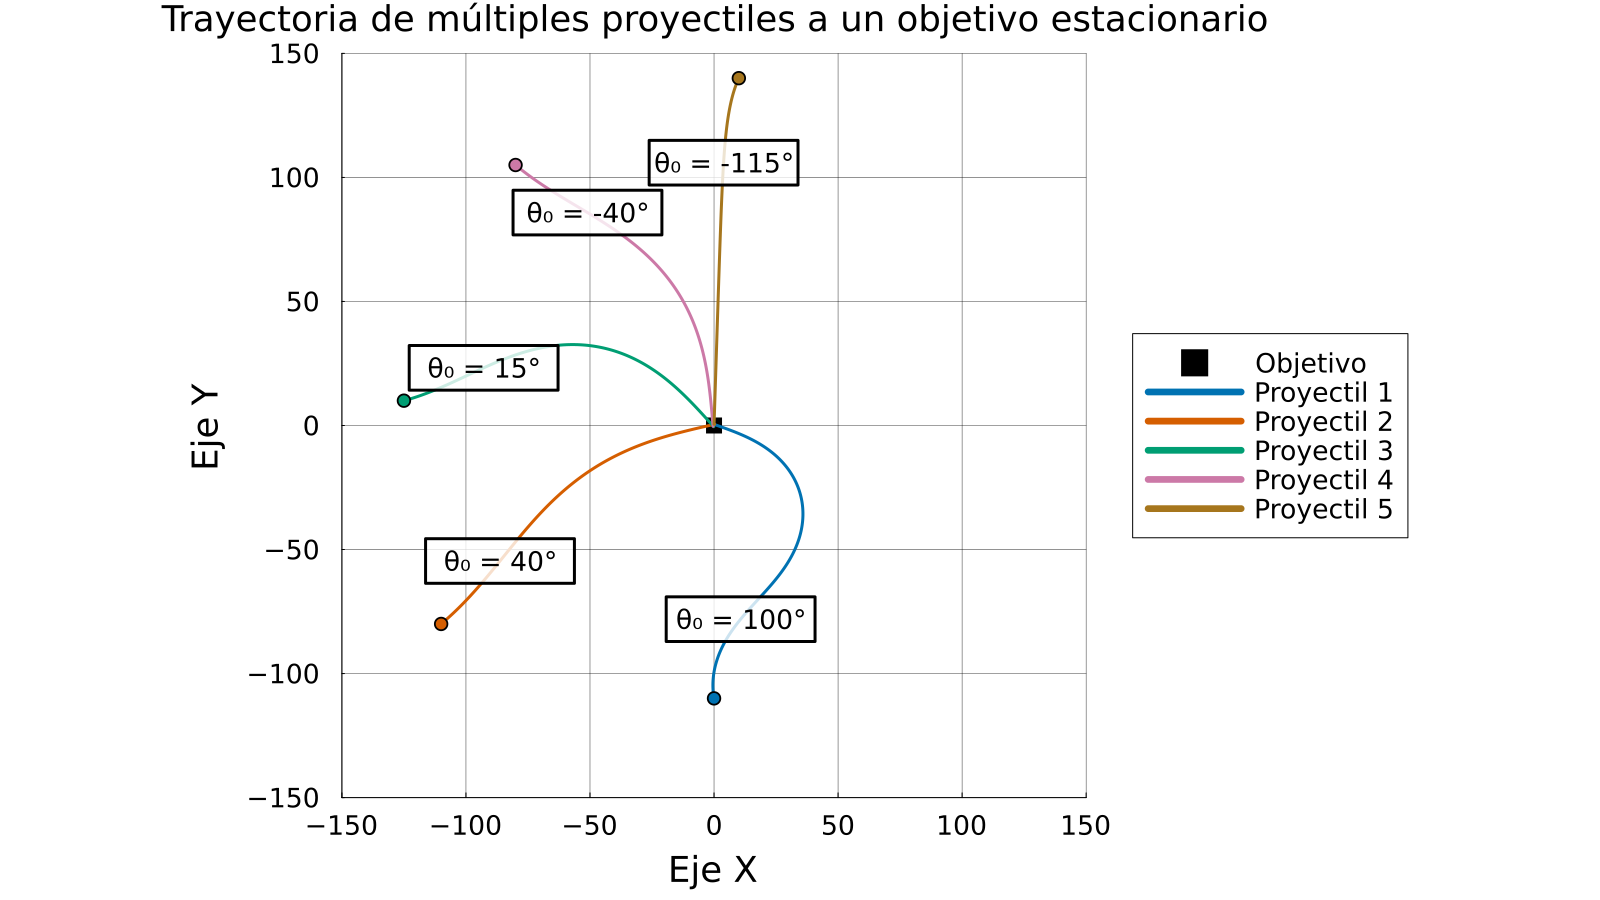


Iteración N = 6:
[[0.0, -110.0, 100.0], [-110.0, -80.0, 40.0], [-125.0, 10.0, 15.0], [-80.0, 105.0, -40.0], [10.0, 140.0, -115.0], [96.0, 72.0, -130.0]]


[ Info: Saved animation to c:\Users\Matias\guiado-proyectiles\outputs\multiproyectil\trayectorias_N5.gif


 38.164321 seconds (10.72 M allocations: 3.289 GiB, 2.34% gc time)
Estado: first_order
Convergencia: true
Restricciones: 7.275957614183426e-12
 38.165045 seconds (10.72 M allocations: 3.289 GiB, 2.34% gc time)


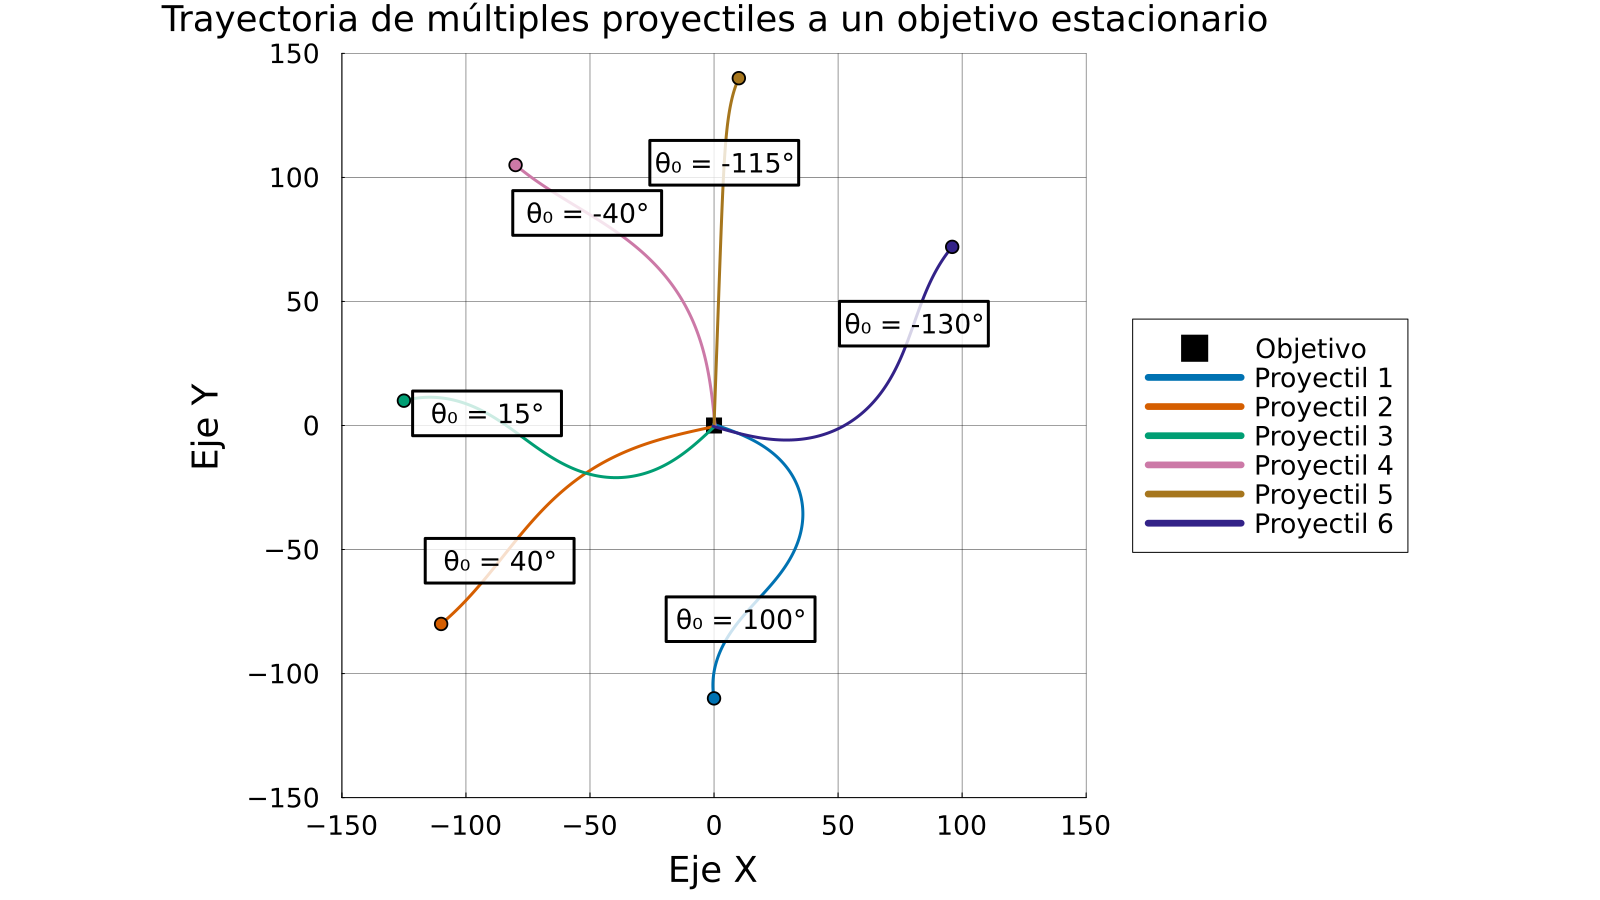


Iteración N = 7:
[[0.0, -110.0, 100.0], [-110.0, -80.0, 40.0], [-125.0, 10.0, 15.0], [-80.0, 105.0, -40.0], [10.0, 140.0, -115.0], [96.0, 72.0, -130.0], [105.0, -10.0, 160.0]]


[ Info: Saved animation to c:\Users\Matias\guiado-proyectiles\outputs\multiproyectil\trayectorias_N6.gif


422.616919 seconds (81.55 M allocations: 19.498 GiB, 0.70% gc time)
Estado: first_order
Convergencia: true
Restricciones: 5.838955985382199e-10
422.617633 seconds (81.55 M allocations: 19.498 GiB, 0.70% gc time)


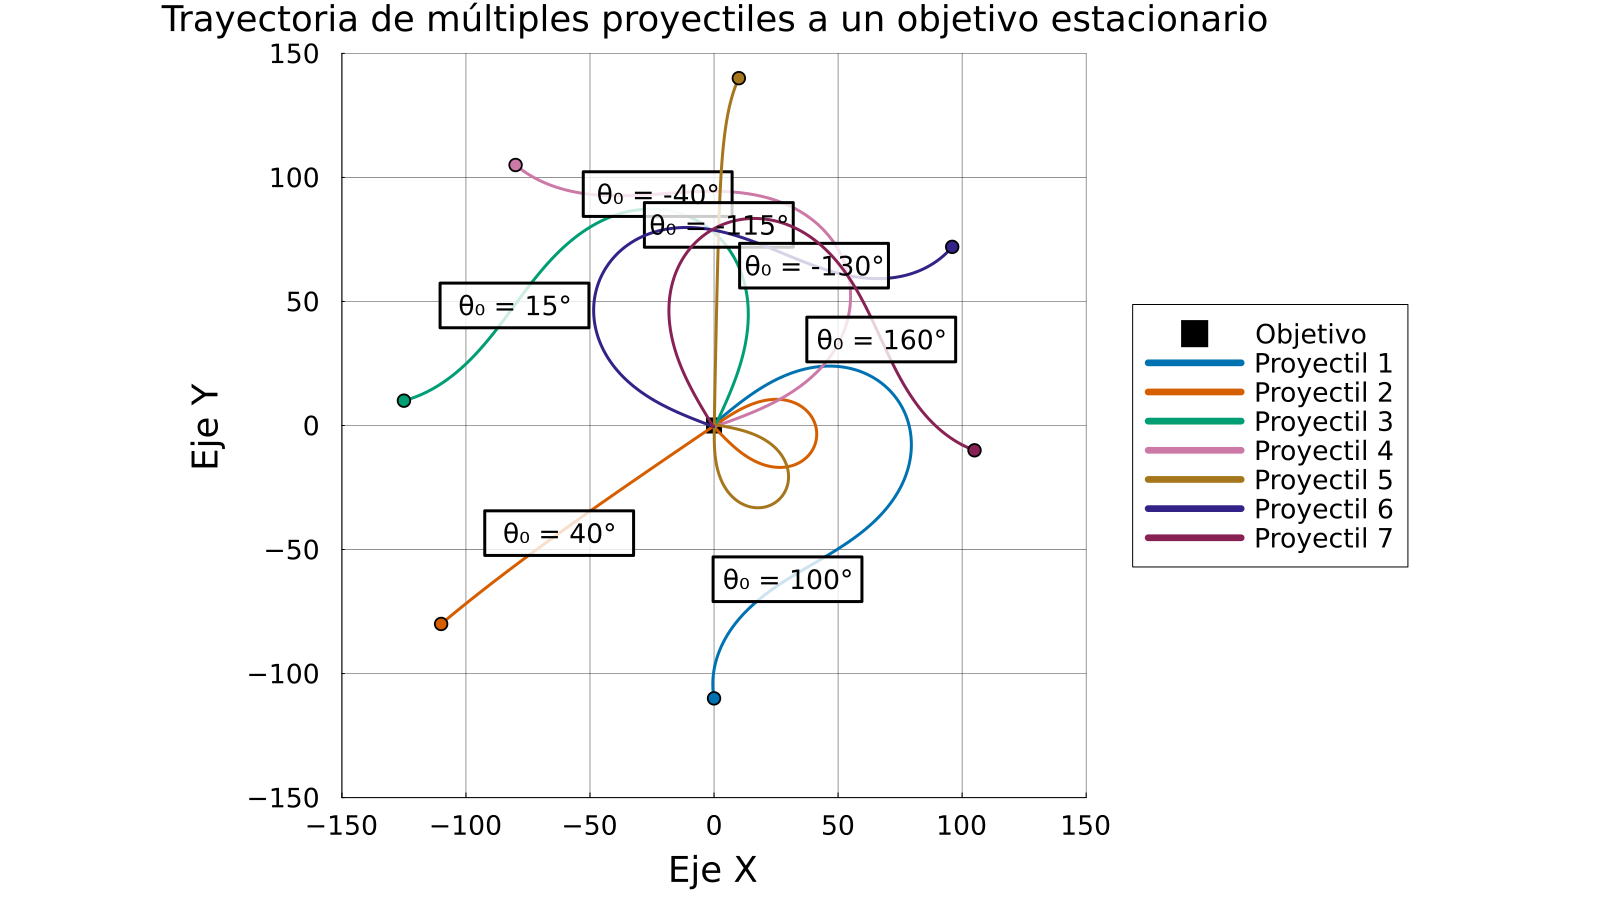


Iteración N = 8:
[[0.0, -110.0, 100.0], [-110.0, -80.0, 40.0], [-125.0, 10.0, 15.0], [-80.0, 105.0, -40.0], [10.0, 140.0, -115.0], [96.0, 72.0, -130.0], [105.0, -10.0, 160.0], [75.0, -100.0, 115.0]]


[ Info: Saved animation to c:\Users\Matias\guiado-proyectiles\outputs\multiproyectil\trayectorias_N7.gif


 61.403093 seconds (18.14 M allocations: 6.425 GiB, 1.82% gc time)
Estado: first_order
Convergencia: true
Restricciones: 3.283275873400271e-10
 61.403823 seconds (18.14 M allocations: 6.425 GiB, 1.82% gc time)


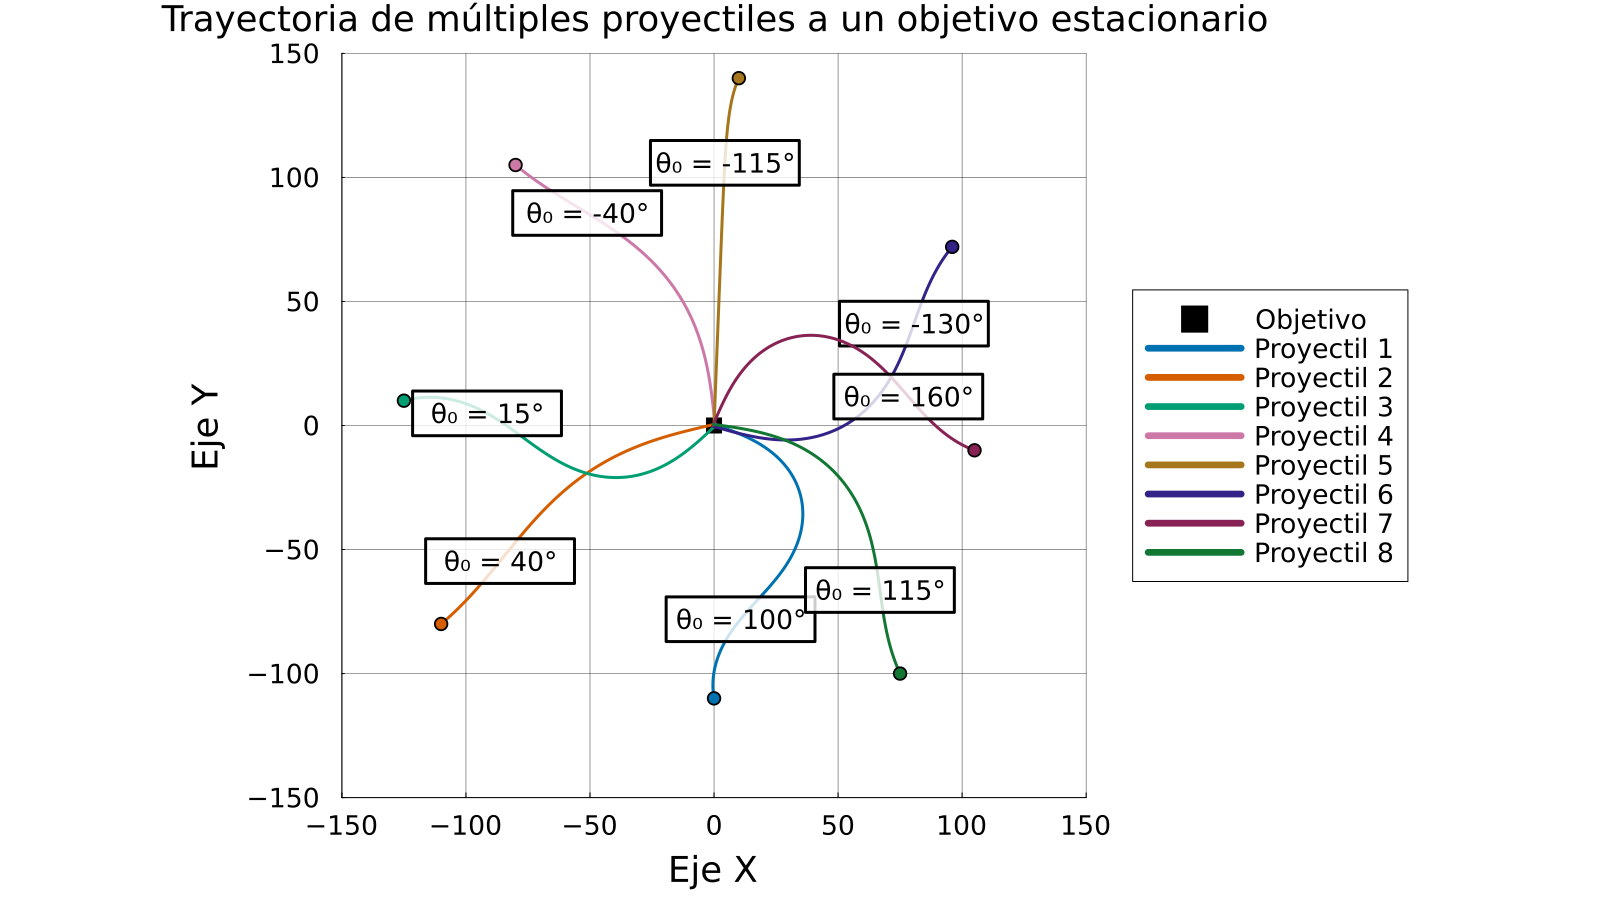

[ Info: Saved animation to c:\Users\Matias\guiado-proyectiles\outputs\multiproyectil\trayectorias_N8.gif


In [ ]:
# Datos del problema
pos_target = [0.0, 0.0]

rapidez_proyectil = 5.0

datos_proyectiles = [
    [  0.0, -110.0,  100.0],  # Sur 
    [-110.0, -80.0,   40.0],  # Suroeste
    [-125.0,  10.0,   15.0],  # Oeste
    [-80.0,  105.0,  -40.0],  # Noroeste
    [ 10.0,  140.0, -115.0],  # Norte
    [ 96.0,   72.0, -130.0],  # Noreste
    [105.0,  -10.0,  160.0],  # Este
    [ 75.0, -100.0,  115.0],  # Sureste
]

condiciones_iniciales = empty(datos_proyectiles)

for i in eachindex(datos_proyectiles)
    println("\nIteración N = $i:")

    push!(condiciones_iniciales, datos_proyectiles[i])
    N = length(condiciones_iniciales)
    println(condiciones_iniciales)

    datos_iniciales = preparar_datos_iniciales(pos_target, condiciones_iniciales)

    # Estimación del tiempo final según el proyectil más lejano
    dist_max = maximum(hypot(datos_iniciales[k], datos_iniciales[N + k]) for k in 1:N)
    tf_estimado = (dist_max / rapidez_proyectil) * 1.15

    problema_multiproyectil = persecucion_multiproyectil_holgura(
        0.0,
        datos_iniciales;
        rapidez_M = rapidez_proyectil,
        max_T = max(35.0, tf_estimado * 1.5)
    )

    sol = @time resolver(problema_multiproyectil)

    display(plot_trayectorias(
        sol, pos_target, condiciones_iniciales;
        lim_x = LIM_X,
        lim_y = LIM_Y,
    ))

    animar_trayectorias(
        sol,
        pos_target,
        condiciones_iniciales;
        lim_x = LIM_X,
        lim_y = LIM_Y,
        archivo = "trayectorias_N$(N).gif"
    )
end

In [6]:
datos_proyectiles = [
    [-10.0, 0.0, 45.0],
    [150.0, 0.0, 225.0], 
]

rapidez_proyectil = 2.0

datos_iniciales = preparar_datos_iniciales(pos_target, datos_proyectiles)

tf_est = (150 / rapidez_proyectil) * 1.15

for gamma in [100, 0.0001]
    problema_multiproyectil = persecucion_multiproyectil_holgura(
        0.0,
        datos_iniciales;
        rapidez_M = rapidez_proyectil,
        gamma = gamma,
        max_T = tf_est * 1.5
    )
    println("gamma = $gamma:")
    sol = resolver(problema_multiproyectil)

    animar_trayectorias(
        sol,
        pos_target,
        datos_proyectiles;
        lim_x = LIM_X,
        lim_y = LIM_Y,
        archivo = "posiciones_lejanas_gamma_$gamma.gif"
    )
end

gamma = 100.0:
167.961511 seconds (51.66 M allocations: 4.460 GiB, 0.62% gc time)
Estado: first_order
Convergencia: true
Restricciones: 4.321623237046879e-8
gamma = 0.0001:


[ Info: Saved animation to c:\Users\Matias\guiado-proyectiles\outputs\multiproyectil\posiciones_lejanas_gamma_100.0.gif


225.398241 seconds (87.21 M allocations: 7.504 GiB, 0.37% gc time)
Estado: max_iter
Convergencia: false
Restricciones: 44.88762133812588


[ Info: Saved animation to c:\Users\Matias\guiado-proyectiles\outputs\multiproyectil\posiciones_lejanas_gamma_0.0001.gif
